# LAB3 — BPE & WordPiece Tokenization on IndicCorpV2 (Hindi)

This notebook is self-contained for **Google Colab**. It:

1. Streams Hindi (`hin_Deva`) data from `ai4bharat/IndicCorpV2`, sentence-tokenizes the paragraphs, and builds train/dev/test splits (dev & test = 1000 sentences each, chosen to cover a spread of sentence lengths, not just short/common ones).
2. Trains **BPE** and **WordPiece** tokenizers on the training data.
3. Repeats training at 4 training-data sizes: 100k / 300k / 500k / 1,000,000 sentences.
4. Repeats training at 3 vocabulary sizes: 20,000 / 30,000 / 50,000.
5. Tokenizes dev & test with every resulting tokenizer and reports comparison tables + plots.

## Do you need Google Drive?

**Yes, strongly recommended.** Streaming ~1M+ sentences from the Hindi split takes a while, and Colab wipes `/content` when the runtime disconnects/recycles. Mount Drive once and everything (raw sentences, splits, trained tokenizers, results) is saved under:

```
/content/drive/MyDrive/LAB3_LangID/
```

so if your session dies you re-run from where you left off instead of re-downloading. You don't need to manually upload anything beforehand — the notebook downloads directly from Hugging Face into Drive. The only thing you might *manually* grab afterwards is the final `results/` folder (tables + plots + tokenizer files), which you can just open from Drive or zip and download from the Colab file browser.

**Runtime:** Runtime → Change runtime type → CPU is fine (no GPU needed for tokenizer training). Set it before running.


## 1. Setup

In [ ]:
!pip install -q datasets huggingface_hub tokenizers


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


If you get a 403/401 error loading the dataset in the next steps, IndicCorpV2 has become gated for your account. Uncomment and run the cell below, then paste a token from https://huggingface.co/settings/tokens (read access is enough). Otherwise skip it.

In [ ]:
# from huggingface_hub import login
# login()  # paste your HF token when prompted


In [ ]:
import os

LANG = "hin_Deva"          # Hindi, Devanagari script
REPO_ID = "ai4bharat/IndicCorpV2"
CONFIG = "indiccorp_v2"

BASE_DIR = "/content/drive/MyDrive/LAB3_LangID"
RAW_DIR = os.path.join(BASE_DIR, "raw")
SPLIT_DIR = os.path.join(BASE_DIR, "splits")
TOK_DIR = os.path.join(BASE_DIR, "tokenizers")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
for d in (RAW_DIR, SPLIT_DIR, TOK_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

DEV_N = 1000
TEST_N = 1000
TRAIN_SIZES = [100_000, 300_000, 500_000, 1_000_000]
MAX_TRAIN = max(TRAIN_SIZES)
POOL_TARGET = MAX_TRAIN + DEV_N + TEST_N  # sentences needed before carving out dev/test

VOCAB_SIZES = [20_000, 30_000, 50_000]
DEFAULT_VOCAB_FOR_SIZE_SWEEP = 30_000       # used for task 3 (varying train size)
DEFAULT_TRAIN_FOR_VOCAB_SWEEP = 1_000_000   # used for task 4 (varying vocab size)

print(f"Need a pool of {POOL_TARGET:,} unique sentences for {LANG}.")


Need a pool of 1,002,000 unique sentences for hin_Deva.


## 2. Sentence tokenizer (rule-based, same approach as LAB1)

In [ ]:
import re

_SENT_END = re.compile(r'([।॥.!?؟۔‽]+)')
_WS = re.compile(r'\s+')

def split_paragraph(text, min_chars=8, min_words=3, max_words=80):
    if not text:
        return []
    text = _WS.sub(' ', text).strip()
    if not text:
        return []

    parts = _SENT_END.split(text)
    sentences = []
    buf = ''
    for part in parts:
        if _SENT_END.fullmatch(part):
            buf = (buf + part).strip()
            if buf:
                sentences.append(buf)
            buf = ''
        else:
            buf += part
    if buf.strip():
        sentences.append(buf.strip())

    out = []
    for s in sentences:
        s = s.strip()
        if len(s) < min_chars:
            continue
        n_words = len(s.split(' '))
        if n_words < min_words or n_words > max_words:
            continue
        out.append(s)
    return out


## 3. Stream sentences from IndicCorpV2 into a pool on Drive

Resumable: if `raw/hin_Deva.txt` on Drive already has enough lines, this cell does nothing.
Otherwise it streams paragraphs, sentence-splits them, dedupes, and writes to Drive every 20k
sentences so progress survives a disconnect (on re-run it reloads what's already saved and
keeps going, though the underlying HF stream restarts from the beginning — already-seen
sentences are skipped cheaply via the `seen` set).

In [ ]:
import time
from datasets import load_dataset

def collect_pool(lang, target, max_docs=5_000_000, checkpoint_every=20_000):
    out_path = os.path.join(RAW_DIR, f"{lang}.txt")

    seen = set()
    sentences = []
    if os.path.exists(out_path):
        with open(out_path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.rstrip("\n")
                if line and line not in seen:
                    seen.add(line)
                    sentences.append(line)
        print(f"Loaded {len(sentences):,} existing sentences from {out_path}")
        if len(sentences) >= target:
            return sentences

    for attempt in range(3):
        try:
            ds = load_dataset(REPO_ID, CONFIG, split=lang, streaming=True)
            break
        except Exception as e:
            print(f"load error ({e}); retry {attempt+1}/3")
            time.sleep(5)
    else:
        raise RuntimeError(f"could not open stream for {lang}")

    n_docs = 0
    last_checkpoint = len(sentences)
    for ex in ds:
        n_docs += 1
        if n_docs > max_docs or len(sentences) >= target:
            break
        text = ex.get("text") or ""
        for s in split_paragraph(text):
            if s in seen:
                continue
            seen.add(s)
            sentences.append(s)
            if len(sentences) >= target:
                break

        if len(sentences) - last_checkpoint >= checkpoint_every:
            with open(out_path, "w", encoding="utf-8") as f:
                f.write("\n".join(sentences) + "\n")
            last_checkpoint = len(sentences)
            print(f"  ...{len(sentences):,}/{target:,} sentences from {n_docs:,} docs")

    with open(out_path, "w", encoding="utf-8") as f:
        f.write("\n".join(sentences) + "\n")
    print(f"Done: {len(sentences):,} sentences from {n_docs:,} docs -> {out_path}")
    return sentences

pool = collect_pool(LANG, POOL_TARGET)
print(f"Pool size: {len(pool):,}")


README.md:   0%|          | 0.00/4.01k [00:00<?, ?B/s]

  ...20,000/1,002,000 sentences from 12,475 docs
  ...40,012/1,002,000 sentences from 24,345 docs
  ...60,025/1,002,000 sentences from 36,597 docs
  ...80,025/1,002,000 sentences from 49,109 docs
  ...100,025/1,002,000 sentences from 61,129 docs
  ...120,025/1,002,000 sentences from 72,903 docs
  ...140,025/1,002,000 sentences from 85,345 docs
  ...160,029/1,002,000 sentences from 97,801 docs
  ...180,033/1,002,000 sentences from 109,987 docs
  ...200,036/1,002,000 sentences from 121,935 docs
  ...220,042/1,002,000 sentences from 134,335 docs
  ...240,046/1,002,000 sentences from 146,967 docs
  ...260,052/1,002,000 sentences from 159,163 docs
  ...280,057/1,002,000 sentences from 171,319 docs
  ...300,064/1,002,000 sentences from 183,209 docs
  ...320,065/1,002,000 sentences from 195,237 docs
  ...340,066/1,002,000 sentences from 207,137 docs
  ...360,066/1,002,000 sentences from 219,719 docs
  ...380,068/1,002,000 sentences from 232,097 docs
  ...400,068/1,002,000 sentences from 244,3

## 4. Build dev/test sets with a spread of sentence lengths

We bin sentences into 10 length buckets (by word count, using quantile edges over the whole
pool) and sample evenly across bins for dev and test, so both sets contain a mix of short and
long sentences instead of clustering around the most common length. The remaining pool becomes
the training pool.

In [ ]:
import random
import numpy as np

SEED = 42
rng = random.Random(SEED)

lengths = np.array([len(s.split(' ')) for s in pool])
n_bins = 10
edges = np.quantile(lengths, np.linspace(0, 1, n_bins + 1))
edges[-1] += 1  # make the top edge inclusive
bin_ids = np.digitize(lengths, edges[1:-1], right=False)  # 0..n_bins-1

by_bin = {b: [] for b in range(n_bins)}
for idx, b in enumerate(bin_ids):
    by_bin[int(b)].append(idx)
for b in by_bin:
    rng.shuffle(by_bin[b])

def take_per_bin(n_total, exclude):
    per_bin = n_total // n_bins
    remainder = n_total - per_bin * n_bins
    chosen = []
    for b in range(n_bins):
        want = per_bin + (1 if b < remainder else 0)
        picked = [i for i in by_bin[b] if i not in exclude][:want]
        chosen.extend(picked)
    return chosen

exclude = set()
dev_idx = take_per_bin(DEV_N, exclude)
exclude.update(dev_idx)
test_idx = take_per_bin(TEST_N, exclude)
exclude.update(test_idx)

dev_sentences = [pool[i] for i in dev_idx]
test_sentences = [pool[i] for i in test_idx]
train_pool = [pool[i] for i in range(len(pool)) if i not in exclude]
rng.shuffle(train_pool)
train_pool = train_pool[:MAX_TRAIN]

print(f"dev={len(dev_sentences)}  test={len(test_sentences)}  train_pool={len(train_pool)}")
print("dev length distribution (words): min={}, median={}, max={}".format(
    min(len(s.split(' ')) for s in dev_sentences),
    int(np.median([len(s.split(' ')) for s in dev_sentences])),
    max(len(s.split(' ')) for s in dev_sentences)))

def write_lines(path, lines):
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")

write_lines(os.path.join(SPLIT_DIR, "dev.txt"), dev_sentences)
write_lines(os.path.join(SPLIT_DIR, "test.txt"), test_sentences)

train_files = {}
for n in TRAIN_SIZES:
    path = os.path.join(SPLIT_DIR, f"train_{n}.txt")
    write_lines(path, train_pool[:n])
    train_files[n] = path
    print(f"wrote {path} ({n:,} sentences)")


dev=1000  test=1000  train_pool=1000000
dev length distribution (words): min=3, median=14, max=70
wrote /content/drive/MyDrive/LAB3_LangID/splits/train_100000.txt (100,000 sentences)
wrote /content/drive/MyDrive/LAB3_LangID/splits/train_300000.txt (300,000 sentences)
wrote /content/drive/MyDrive/LAB3_LangID/splits/train_500000.txt (500,000 sentences)
wrote /content/drive/MyDrive/LAB3_LangID/splits/train_1000000.txt (1,000,000 sentences)


## 5. Train BPE & WordPiece tokenizers

Grid: `{100k, 300k, 500k, 1M} train sentences × {20k, 30k, 50k} vocab size × {BPE, WordPiece}`
= 24 tokenizers. Uses the Rust-backed `tokenizers` library (from-scratch pure-Python BPE/WordPiece
training would be far too slow at this scale).

In [ ]:
from tokenizers import Tokenizer
from tokenizers.models import BPE, WordPiece
from tokenizers.trainers import BpeTrainer, WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace

SPECIAL_TOKENS = ["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"]

def train_tokenizer(algo, files, vocab_size):
    if algo == "bpe":
        tok = Tokenizer(BPE(unk_token="[UNK]"))
        trainer = BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS,
                              show_progress=False)
    elif algo == "wordpiece":
        tok = Tokenizer(WordPiece(unk_token="[UNK]"))
        trainer = WordPieceTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS,
                                    show_progress=False)
    else:
        raise ValueError(algo)
    tok.pre_tokenizer = Whitespace()
    tok.train(files, trainer)
    return tok

def tok_path(algo, train_size, vocab_size):
    return os.path.join(TOK_DIR, f"{algo}_train{train_size}_vocab{vocab_size}.json")

# Build the grid, but reuse what's already trained on Drive.
grid = []
for train_size in TRAIN_SIZES:
    for vocab_size in VOCAB_SIZES:
        # only the "task 3" sweep needs every train_size (at DEFAULT vocab), and only the
        # "task 4" sweep needs every vocab_size (at DEFAULT train_size) -- but training the
        # full cross product gives richer comparisons for ~free, so we do all combos.
        grid.append((train_size, vocab_size))

for algo in ("bpe", "wordpiece"):
    for train_size, vocab_size in grid:
        path = tok_path(algo, train_size, vocab_size)
        if os.path.exists(path):
            continue
        t0 = time.time()
        tok = train_tokenizer(algo, [train_files[train_size]], vocab_size)
        tok.save(path)
        print(f"[{algo}] train={train_size:>9,} vocab={vocab_size:>6,} "
              f"actual_vocab={tok.get_vocab_size():>6,}  ({time.time()-t0:.1f}s)")


[bpe] train=  100,000 vocab=20,000 actual_vocab=20,000  (5.3s)
[bpe] train=  100,000 vocab=30,000 actual_vocab=30,000  (3.2s)
[bpe] train=  100,000 vocab=50,000 actual_vocab=50,000  (2.7s)
[bpe] train=  300,000 vocab=20,000 actual_vocab=20,000  (7.5s)
[bpe] train=  300,000 vocab=30,000 actual_vocab=30,000  (6.2s)
[bpe] train=  300,000 vocab=50,000 actual_vocab=50,000  (7.5s)
[bpe] train=  500,000 vocab=20,000 actual_vocab=20,000  (9.7s)
[bpe] train=  500,000 vocab=30,000 actual_vocab=30,000  (11.6s)
[bpe] train=  500,000 vocab=50,000 actual_vocab=50,000  (11.9s)
[bpe] train=1,000,000 vocab=20,000 actual_vocab=20,000  (19.8s)
[bpe] train=1,000,000 vocab=30,000 actual_vocab=30,000  (21.9s)
[bpe] train=1,000,000 vocab=50,000 actual_vocab=50,000  (20.4s)
[wordpiece] train=  100,000 vocab=20,000 actual_vocab=20,000  (2.7s)
[wordpiece] train=  100,000 vocab=30,000 actual_vocab=30,000  (3.9s)
[wordpiece] train=  100,000 vocab=50,000 actual_vocab=50,000  (2.7s)
[wordpiece] train=  300,000 voca

## 6. Tokenize dev & test, compute comparison metrics

For every (algorithm, train_size, vocab_size) we tokenize the dev+test sentences and report:

- **avg tokens/sentence** — how many subword pieces a sentence breaks into
- **fertility** — tokens per whitespace word (higher = more fragmentation)
- **UNK rate** — % of tokens that fell back to `[UNK]`
- **chars/token** — compression ratio


In [ ]:
import pandas as pd

eval_sentences = dev_sentences + test_sentences
eval_word_count = sum(len(s.split(' ')) for s in eval_sentences)
eval_char_count = sum(len(s) for s in eval_sentences)

rows = []
for algo in ("bpe", "wordpiece"):
    for train_size, vocab_size in grid:
        path = tok_path(algo, train_size, vocab_size)
        tok = Tokenizer.from_file(path)
        unk_id = tok.token_to_id("[UNK]")

        total_tokens = 0
        unk_tokens = 0
        for s in eval_sentences:
            ids = tok.encode(s).ids
            total_tokens += len(ids)
            unk_tokens += sum(1 for i in ids if i == unk_id)

        rows.append({
            "algo": algo,
            "train_size": train_size,
            "vocab_size": vocab_size,
            "actual_vocab": tok.get_vocab_size(),
            "avg_tokens_per_sentence": total_tokens / len(eval_sentences),
            "fertility_tokens_per_word": total_tokens / eval_word_count,
            "unk_rate_pct": 100 * unk_tokens / total_tokens,
            "chars_per_token": eval_char_count / total_tokens,
        })

results = pd.DataFrame(rows)
results_path = os.path.join(RESULTS_DIR, "tokenization_comparison.csv")
results.to_csv(results_path, index=False)
results.sort_values(["algo", "train_size", "vocab_size"])


,algo,train_size,vocab_size,actual_vocab,avg_tokens_per_sentence,fertility_tokens_per_word,unk_rate_pct,chars_per_token
0,bpe,100000,20000,20000,19.8880,1.189225,0.005028,4.226870
1,bpe,100000,30000,30000,19.4405,1.162466,0.005144,4.324169
2,bpe,100000,50000,50000,19.0975,1.141956,0.005236,4.401833
3,bpe,300000,20000,20000,19.8605,1.187580,0.005035,4.232723
4,bpe,300000,30000,30000,19.3795,1.158818,0.005160,4.337780
5,bpe,300000,50000,50000,19.0235,1.137531,0.005257,4.418956
6,bpe,500000,20000,20000,19.8630,1.187730,0.005034,4.232191
7,bpe,500000,30000,30000,19.3735,1.158460,0.005162,4.339123
8,bpe,500000,50000,50000,19.0050,1.136425,0.005262,4.423257
9,bpe,1000000,20000,20000,19.8635,1.187760,0.002517,4.232084


### Task 3 — effect of training data size (vocab size fixed at 30,000)

In [ ]:
size_sweep = results[results.vocab_size == DEFAULT_VOCAB_FOR_SIZE_SWEEP] \
    .sort_values(["algo", "train_size"])
size_sweep


,algo,train_size,vocab_size,actual_vocab,avg_tokens_per_sentence,fertility_tokens_per_word,unk_rate_pct,chars_per_token
1,bpe,100000,30000,30000,19.4405,1.162466,0.005144,4.324169
4,bpe,300000,30000,30000,19.3795,1.158818,0.005160,4.337780
7,bpe,500000,30000,30000,19.3735,1.158460,0.005162,4.339123
10,bpe,1000000,30000,30000,19.3745,1.158519,0.002581,4.338899
13,wordpiece,100000,30000,30000,19.5995,1.171974,0.005102,4.289089
16,wordpiece,300000,30000,30000,19.5550,1.169313,0.005114,4.298849
19,wordpiece,500000,30000,30000,19.5535,1.169223,0.005114,4.299179
22,wordpiece,1000000,30000,30000,19.5690,1.170150,0.002555,4.295774


### Task 4 — effect of vocabulary size (training size fixed at 1,000,000)

In [ ]:
vocab_sweep = results[results.train_size == DEFAULT_TRAIN_FOR_VOCAB_SWEEP] \
    .sort_values(["algo", "vocab_size"])
vocab_sweep


,algo,train_size,vocab_size,actual_vocab,avg_tokens_per_sentence,fertility_tokens_per_word,unk_rate_pct,chars_per_token
9,bpe,1000000,20000,20000,19.8635,1.187760,0.002517,4.232084
10,bpe,1000000,30000,30000,19.3745,1.158519,0.002581,4.338899
11,bpe,1000000,50000,50000,18.9990,1.136066,0.002632,4.424654
21,wordpiece,1000000,20000,20000,20.1850,1.206984,0.002477,4.164677
22,wordpiece,1000000,30000,30000,19.5690,1.170150,0.002555,4.295774
23,wordpiece,1000000,50000,50000,19.1105,1.142733,0.002616,4.398838


## 7. Plots

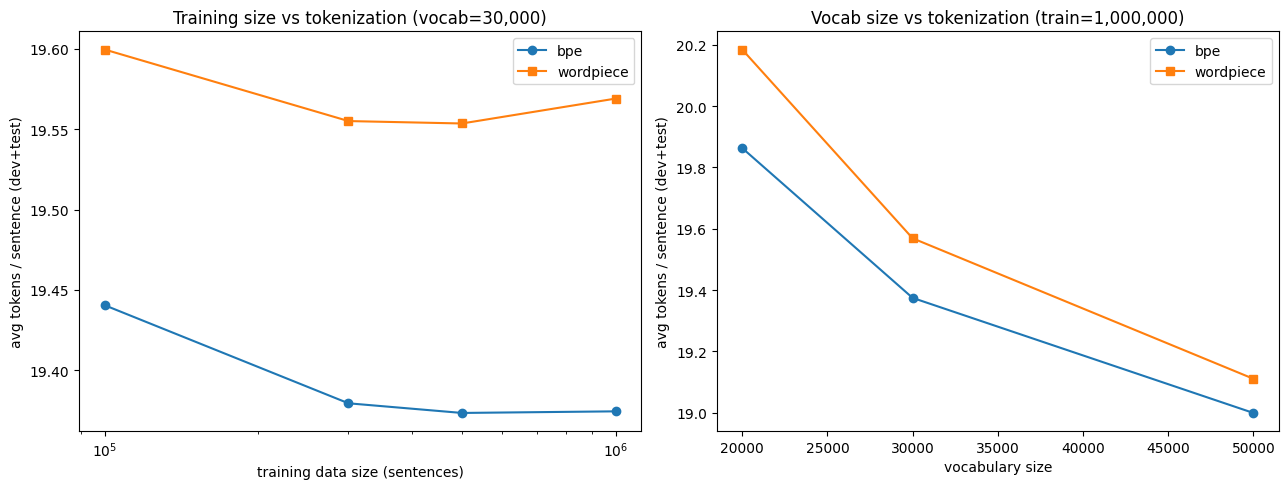

saved /content/drive/MyDrive/LAB3_LangID/results/tokenization_plots.png


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for algo, marker in [("bpe", "o"), ("wordpiece", "s")]:
    sub = size_sweep[size_sweep.algo == algo]
    axes[0].plot(sub.train_size, sub.avg_tokens_per_sentence, marker=marker, label=algo)
axes[0].set_xlabel("training data size (sentences)")
axes[0].set_ylabel("avg tokens / sentence (dev+test)")
axes[0].set_title(f"Training size vs tokenization (vocab={DEFAULT_VOCAB_FOR_SIZE_SWEEP:,})")
axes[0].set_xscale("log")
axes[0].legend()

for algo, marker in [("bpe", "o"), ("wordpiece", "s")]:
    sub = vocab_sweep[vocab_sweep.algo == algo]
    axes[1].plot(sub.vocab_size, sub.avg_tokens_per_sentence, marker=marker, label=algo)
axes[1].set_xlabel("vocabulary size")
axes[1].set_ylabel("avg tokens / sentence (dev+test)")
axes[1].set_title(f"Vocab size vs tokenization (train={DEFAULT_TRAIN_FOR_VOCAB_SWEEP:,})")
axes[1].legend()

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, "tokenization_plots.png")
plt.savefig(plot_path, dpi=150)
plt.show()
print(f"saved {plot_path}")


## 8. Qualitative check — same sentence under every tokenizer

Useful to eyeball in your report: pick a couple of dev sentences of different lengths and show
how each (algo, vocab_size) at the full 1M training size segments them.

In [ ]:
sample_sentences = sorted(dev_sentences, key=lambda s: len(s.split(' ')))[::len(dev_sentences)//3][:3]

for s in sample_sentences:
    print(f"\nSENTENCE ({len(s.split(' '))} words): {s}")
    for algo in ("bpe", "wordpiece"):
        for vocab_size in VOCAB_SIZES:
            tok = Tokenizer.from_file(tok_path(algo, DEFAULT_TRAIN_FOR_VOCAB_SWEEP, vocab_size))
            pieces = tok.encode(s).tokens
            print(f"  [{algo:9s} vocab={vocab_size:>6,}] ({len(pieces):>3} tok) {pieces}")



SENTENCE (3 words): मेडन (इंडोनेशिया), (एएफपी)।
  [bpe       vocab=20,000] (  9 tok) ['मे', 'डन', '(', 'इंडोनेशिया', '),', '(', 'एएफ', 'पी', ')।']
  [bpe       vocab=30,000] (  9 tok) ['मे', 'डन', '(', 'इंडोनेशिया', '),', '(', 'एएफ', 'पी', ')।']
  [bpe       vocab=50,000] (  7 tok) ['मेडन', '(', 'इंडोनेशिया', '),', '(', 'एएफपी', ')।']
  [wordpiece vocab=20,000] ( 10 tok) ['मेड', '##न', '(', 'इंडोनेशिया', '),', '(', 'ए', '##एफ', '##पी', ')।']
  [wordpiece vocab=30,000] (  9 tok) ['मेड', '##न', '(', 'इंडोनेशिया', '),', '(', 'एएफ', '##पी', ')।']
  [wordpiece vocab=50,000] (  7 tok) ['मेडन', '(', 'इंडोनेशिया', '),', '(', 'एएफपी', ')।']

SENTENCE (11 words): बड़े बुजुर्गों को भी इसी वजह से नाराज़ बिलकुल न करें.
  [bpe       vocab=20,000] ( 13 tok) ['बड़े', 'बुजुर्गों', 'को', 'भी', 'इसी', 'वजह', 'से', 'नारा', 'ज़', 'बिलकुल', 'न', 'करें', '.']
  [bpe       vocab=30,000] ( 12 tok) ['बड़े', 'बुजुर्गों', 'को', 'भी', 'इसी', 'वजह', 'से', 'नाराज़', 'बिलकुल', 'न', 'करें', '.']
  [bpe       vocab=50,000] 

## 9. Everything saved on Drive

- `raw/hin_Deva.txt` — full deduped sentence pool streamed from IndicCorpV2
- `splits/dev.txt`, `splits/test.txt` — length-stratified 1000-sentence sets
- `splits/train_{100000,300000,500000,1000000}.txt` — nested training subsets
- `tokenizers/{bpe,wordpiece}_train{N}_vocab{V}.json` — all 24 trained tokenizers
- `results/tokenization_comparison.csv` — full metrics grid
- `results/tokenization_plots.png` — the two comparison plots

Everything above lives under `/content/drive/MyDrive/LAB3_LangID/` — open that folder in Drive
directly, or zip it from a Colab cell (`!zip -r results.zip /content/drive/MyDrive/LAB3_LangID/results`)
if you want a single file to download.